# Fine-tuning a Transformer with the Hugging Face `Trainer`

**Problem.** A patent search should treat *"opc drum"* and *"inorganic photoconductor drum"* as near-synonyms, and the meaning of a phrase can depend on the technical field. The [U.S. Patent Phrase to Phrase Matching](https://www.kaggle.com/competitions/us-patent-phrase-to-phrase-matching) data gives an **anchor** phrase, a **target** phrase, a **context** (a CPC patent-classification code such as `G02`), and an expert similarity **score** in {0, 0.25, 0.5, 0.75, 1}. We fine-tune a pretrained Transformer to predict that score.

**Concepts**

1. The data: what each column means, what the score measures, and what we are trying to predict.
2. Framing the task as **regression or classification**, the loss each framing uses, and how the loss relates to the evaluation metric.
3. Preparing inputs: sentence pairs, **special tokens built from the context column**, and resizing the embedding matrix.
4. **Grouped, stratified K-fold** validation, and why a random split would mislead us.
5. The `Trainer` building blocks: `Dataset.map`, dynamic padding, `TrainingArguments`, `compute_metrics`.
6. Training, reading the logs, out-of-fold predictions, and saving and reloading for inference.

**Prerequisites:** BERT-style encoders, tokenization, and `[CLS]`/`[SEP]` (Module 2).

**Runtime:** Kaggle notebook with **GPU T4/P100 and internet on**. Attach the competition data with **Add Input → Competitions**. The demo trains **one fold for two epochs**, which takes a few minutes on a T4. Downloads `microsoft/deberta-v3-small` (MIT license) from the Hugging Face Hub. Writes checkpoints and the final model to `/kaggle/working/hf_trainer_demo/`; a rerun overwrites them.

In [30]:
import glob

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import transformers
from datasets import Dataset
from sklearn.model_selection import KFold, StratifiedGroupKFold
from tokenizers.processors import TemplateProcessing
from transformers import (AutoModelForSequenceClassification, AutoTokenizer,
                          DataCollatorWithPadding, Trainer, TrainingArguments)

SEED = 42
transformers.set_seed(SEED)   # seeds Python/NumPy/PyTorch; GPU kernels can still make runs differ slightly
print("torch", torch.__version__, "| transformers", transformers.__version__,
      "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

MODEL_ID = "microsoft/deberta-v3-small"
OUT_DIR = "/kaggle/working/hf_trainer_demo"
N_FOLDS, TRAIN_FOLDS = 5, [0]        # set TRAIN_FOLDS = range(N_FOLDS) for full cross-validation
EPOCHS, MAX_LEN = 2, 64

def find_train_csv(root="/kaggle/input"):
    """Find the USPPPM train.csv by its columns, whatever folder Kaggle mounted it under."""
    for path in sorted(glob.glob(f"{root}/**/train.csv", recursive=True)):
        if {"anchor", "target", "context", "score"} <= set(pd.read_csv(path, nrows=0).columns):
            return path
    found = sorted(glob.glob(f"{root}/**/*.csv", recursive=True))
    raise FileNotFoundError("USPPPM train.csv not found. Add it with Add Input -> Competitions -> "
                            f"'U.S. Patent Phrase to Phrase Matching'. CSV files under {root}: {found[:10]}")


train_csv = find_train_csv()
print("data:", train_csv)
df = pd.read_csv(train_csv)
print(df.shape, "| distinct anchors:", df.anchor.nunique())
df.head()

torch 2.10.0+cu128 | transformers 5.0.0 | GPU: Tesla T4
data: /kaggle/input/competitions/us-patent-phrase-to-phrase-matching/train.csv
(36473, 5) | distinct anchors: 733


,id,anchor,target,context,score
0,37d61fd2272659b1,abatement,abatement of pollution,A47,0.50
1,7b9652b17b68b7a4,abatement,act of abating,A47,0.75
2,36d72442aefd8232,abatement,active catalyst,A47,0.25
3,5296b0c19e1ce60e,abatement,eliminating process,A47,0.50
4,54c1e3b9184cb5b6,abatement,forest region,A47,0.00


## 1. The data and the objective

### Where the data comes from

Google released this dataset to help build patent search that matches *meaning*, not just keywords (Aslanyan & Wetherbee, 2022). It was built in three steps:

1. **Anchors.** Important phrases, mostly short noun phrases such as *"lifting assembly"*, were extracted from patents. Phrases appearing in at least 100 patents were kept, and about 1,000 of them were sampled as anchors.
2. **Targets.** Candidate targets came from phrases that share some words with the anchor (*"abatement"* → *"noise abatement"*) and from a BERT masked-language model asked to fill in the anchor's place in patent sentences. The raters also wrote targets of their own.
3. **Ratings.** Two raters rated each pre-generated pair *given the context*, then met to agree on the pairs where they differed.

The dataset deliberately includes hard cases:

- **Ambiguous phrases**, where the field decides the meaning: *"mouse"* is an animal or an input device.
- **Shared keywords without shared meaning:** *"container section"* vs *"kitchen container"*.
- **Hard negatives:** pairs that BERT found similar but the experts did not.

So a model that only counts overlapping words will do badly.

### The columns

| Column | What it holds | In `train.csv` |
| --- | --- | --- |
| `id` | A unique row identifier. Not a feature. | 36,473 rows |
| `anchor` | The first phrase. | 733 distinct anchors, each paired with 1 to 152 targets (median 47) |
| `target` | The second phrase, to be compared with the anchor. | Mostly 1–3 words |
| `context` | A **CPC class**: the technical field in which similarity is judged. | 106 distinct classes |
| `score` | The experts' similarity rating. **This is the label we predict.** | 0, 0.25, 0.5, 0.75 or 1 |

**The context column.** The Cooperative Patent Classification (CPC) is a hierarchy of technical fields: section → class → subclass → group. The context gives the first two levels: a **section letter** followed by a two-digit **class**. For example, `G02` is section G (Physics), class 02 (Optics). The data uses eight sections:

| Section | Field | Section | Field |
| --- | --- | --- | --- |
| A | Human necessities | E | Fixed constructions |
| B | Performing operations; transporting | F | Mechanical engineering; lighting; heating; weapons; blasting |
| C | Chemistry; metallurgy | G | Physics |
| D | Textiles; paper | H | Electricity |

The same anchor can occur under several contexts: *"opc drum"* appears under F16, G02 and G03. Its targets are rated separately in each field.

In [31]:
print("distinct contexts:", df.context.nunique(), "| sections:", sorted(df.context.str[0].unique()))
print("targets per anchor:", df.groupby("anchor").size().describe()[["min", "50%", "max"]].to_dict())
df[df.anchor == "opc drum"].groupby("score").target.apply(lambda t: list(t[:3]))   # one anchor: a few targets at each score

distinct contexts: 106 | sections: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H']
targets per anchor: {'min': 1.0, '50%': 47.0, 'max': 152.0}


score
0.00                         [body, drum brake, drum kit]
0.25                              [actuator, axle, drive]
0.50      [color image creator, copier device part, drum]
0.75    [carbon based photoconductor drum, copier opc ...
Name: target, dtype: object

### The label: what a score means

The experts chose one of five similarity levels, several of which are divided into named relations. The competition gives only the numeric score. The examples are from the dataset paper (anchor → target, context):

| `score` | Level | Relations included | Example |
| --- | --- | --- | --- |
| 1.00 | Very high | Essentially the same phrase | acid absorption → absorption of acid (B08) |
| 0.75 | High | Close synonym | gasoline blend → petrol blend (C10) |
| 0.50 | Medium | Hyponym (broad → narrow), hypernym (narrow → broad), structural match | gasoline blend → fuel blend (C10) |
| 0.25 | Low | Antonym, meronym (a part of), holonym (a whole of), same high-level domain | faucet assembly → water supply (A22) |
| 0.00 | Not related | — | acid absorption → acid reflux (B08) |

Three properties of this label shape everything that follows:

- **Ordered and evenly spaced.** 0.75 is closer to 1.0 than 0.25 is. It is a *graded* similarity, not five unrelated categories.
- **Judged in context.** The same two phrases could get different scores under different CPC classes.
- **Imbalanced.** The counts below show that 0.25 and 0.5 make up about two thirds of the rows, while 1.0 makes up only about 3%. Antonyms score 0.25, not 0: they are related concepts.

In [32]:
print(df.score.value_counts().sort_index())   # imbalanced: few 1.0s, so the model sees few near-synonyms

score
0.00     7471
0.25    11519
0.50    12300
0.75     4029
1.00     1154
Name: count, dtype: int64


### Our objective

Given an (anchor, target, context) triple, predict a similarity score that agrees with the experts **for anchors the model has never seen**. The competition's hidden test set uses new anchors, because the official split kept all rows of an anchor together. The `test.csv` you can see has only 36 example rows; Kaggle swaps in the real test set when it scores a submission.

Predictions are scored with the **Pearson correlation** between predicted and true scores:

$$r = \frac{\sum_i (\hat y_i - \bar{\hat y})(y_i - \bar y)}{\sqrt{\sum_i (\hat y_i - \bar{\hat y})^2}\,\sqrt{\sum_i (y_i - \bar y)^2}}$$

Here $\hat y_i$ is the prediction for pair $i$, $y_i$ the true score, and bars are means. $r = 1$ means the predictions lie on a rising straight line against the truth; $r = 0$ means no linear relationship. Because the means are subtracted and the result is divided by the spreads, **adding a constant to every prediction or multiplying all of them by a positive number does not change $r$**. What matters is that more similar pairs get higher predictions, in roughly proportional steps. That is what a search engine needs: a reliable ordering of candidate matches.

## 2. Framing the task: regression or classification?

`AutoModelForSequenceClassification` loads the pretrained encoder and adds a new, randomly initialized linear **head** on top of the pooled representation of the sequence. `num_labels` sets the number of head outputs. Together with the dtype of the labels, it decides which loss the model computes:

| `num_labels` | Labels | Loss chosen by `transformers` |
| --- | --- | --- |
| 1 | float | Mean squared error (regression) |
| > 1 | integer class indices | Cross-entropy (single-label classification) |

Because the score takes only five values, the task can be framed in more than one way:

| Framing | Head output | Training target | Loss | Score used for Pearson |
| --- | --- | --- | --- | --- |
| **Regression** (ours) | 1 number $\hat y$ | the score $y$ | MSE: $(\hat y - y)^2$ | $\hat y$ |
| Regression on [0, 1] | 1 logit $z$ | the score $y$ as a soft target | Binary cross-entropy: $-[y \log \sigma(z) + (1-y)\log(1-\sigma(z))]$ | $\sigma(z)$ |
| 5-class classification | 5 logits → probabilities $p_0..p_4$ | class $k = 4y$ (0–4) | Cross-entropy: $-\log p_k$ | $\arg\max_k$ (only 5 values), or the expected score $\sum_k p_k \cdot k/4$ |

Each loss is averaged over the batch. The middle row is not a `transformers` default, so it needs a custom loss function. $\sigma$ is the sigmoid, which keeps the prediction inside [0, 1].

**Why we choose regression.**

1. **It uses the order of the labels.** Cross-entropy only looks at the probability given to the *correct* class, so it does not care which wrong class gets the rest. Predicting 0.75 for a true 1.0 is penalized as heavily as predicting 0. MSE grows with the distance from the truth. The cell below shows this.
2. **It produces the continuous ranking that Pearson needs.** Taking the argmax of a classifier gives only five distinct values, with many ties. Taking the expected score avoids that, but then you are turning the classifier back into a regressor.
3. **It is the simplest.** One output and the built-in loss; no custom code.

Classification is still a reasonable experiment, and so is the binary cross-entropy variant, but regression is the natural starting point.

In [33]:
import torch.nn.functional as F

# One pair with true score 1.0 (class 4), and two classifiers that both give it probability 0.10.
values = torch.tensor([0.0, 0.25, 0.5, 0.75, 1.0])
true_class, true_score = torch.tensor([4]), torch.tensor([1.0])
near_miss = torch.tensor([[0.05, 0.05, 0.10, 0.70, 0.10]])   # mostly says 0.75: one step off
far_miss = torch.tensor([[0.70, 0.05, 0.10, 0.05, 0.10]])    # mostly says 0.00: four steps off

for name, p in [("near miss", near_miss), ("far miss", far_miss)]:
    ce = F.nll_loss(p.log(), true_class)               # cross-entropy = -log p(true class)
    expected = (p * values).sum(-1)                    # turn the probabilities into one score
    print(f"{name}: cross-entropy {ce:.3f} | expected score {expected.item():.3f} | "
          f"squared error {F.mse_loss(expected, true_score):.3f}")

near miss: cross-entropy 2.303 | expected score 0.688 | squared error 0.098
far miss: cross-entropy 2.303 | expected score 0.200 | squared error 0.640


Both classifiers have the **same cross-entropy**, because both give the correct class 10% probability. Measured as a score, the near miss is off by about 0.31 and the far miss by 0.80, and the squared error tells them apart. A regression model is trained on exactly this kind of distance.

**Loss vs. metric.** The model **minimizes MSE** during training, but we **evaluate with Pearson's r**. They are not the same. MSE also penalizes predictions that are shifted or scaled, while Pearson ignores both. Lower MSE usually goes with higher r, but not always. We cannot simply train on Pearson either: it is computed over a whole set of predictions, not one example at a time, and a small batch gives a noisy estimate of it. So we train on a well-behaved per-example **surrogate** loss and measure the metric we care about at evaluation time.

## 3. Preparing the input: sentence pairs and special tokens from the context

The model only sees token IDs, so we must decide how to put three fields (anchor, target and context) into one sequence of tokens.

**Both phrases in one sequence.** A **cross-encoder** reads the two phrases together, so self-attention can compare their tokens directly:

```
[CLS]  [G]  opc drum  [SEP]  inorganic photoconductor drum  [SEP]
       └ section ┘ └ text_a ┘        └──────── text_b ────────┘
```

The alternative is a **bi-encoder**, which embeds each phrase on its own and compares the two vectors with cosine similarity. That was how the baselines in the dataset paper worked. Cross-encoders are usually more accurate at scoring a pair. Bi-encoders are much faster for searching a large collection, because each phrase is embedded only once.

**Adding the context.** A pretrained model has never been taught what `G02` means. There are several ways to put the context into the input:

| Option | `text_a` for *opc drum* under `G02` | Trade-off |
| --- | --- | --- |
| Ignore it | `opc drum` | Loses the field, which the experts used when rating |
| Raw code as text | `G02 opc drum` | Split into subword pieces that carry no learned meaning |
| CPC title as text | `physics optics opc drum` | Words the model already understands, but needs a lookup table of CPC titles and makes inputs longer |
| **Section as a new special token** (ours) | `[G] opc drum` | Short; one learned embedding per section, but coarser than the class |

We use only the **section** (the first letter), not the full class. The counts below show why. The rarest of the 106 classes has only 18 training rows, too few to learn a good embedding for a new token. The rarest section, D, has over 1,200.

**Extracting the special tokens from the data** takes four steps:

1. Take the first character of `context`: `"G02"` → `"G"`.
2. Collect the distinct sections in the data, sorted: A … H.
3. Wrap each one in brackets: `"[A]"` … `"[H]"`.
4. Register them with `tokenizer.add_special_tokens`.

Building the list from the data, rather than typing it, guarantees that every section in the data has a token. That includes test rows, since all 106 classes appear in the training data.

**Why a special token, and not just text?**

- **It is never split.** The tokenizer would otherwise cut `[G]` into `▁[`, `G`, `]`, three pieces that each mean something else. As a special token, it becomes **one token at one position**.
- **It gets its own embedding row**, which fine-tuning trains to carry the "field" signal for that section.
- **It cannot collide with ordinary text.** The brackets keep `[A]` distinct from the word "a".
- Like `[CLS]` and `[SEP]`, it is dropped by `tokenizer.decode(..., skip_special_tokens=True)`.

In [34]:
section = df.context.str[0]                                  # "G02" -> "G"
print("rows per section:", section.value_counts().sort_index().to_dict())
print("rows in the rarest context class:", df.context.value_counts().min())

rows per section: {'A': 4094, 'B': 8019, 'C': 5288, 'D': 1279, 'E': 1531, 'F': 4054, 'G': 6013, 'H': 6195}
rows in the rarest context class: 18


In [35]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
print("before:", tokenizer.tokenize("[G] opc drum"))

section_tokens = [f"[{s}]" for s in sorted(df.context.str[0].unique())]
tokenizer.add_special_tokens({"additional_special_tokens": section_tokens})
print("after: ", tokenizer.tokenize("[G] opc drum"))

# Insert [CLS] and [SEP] around a pair explicitly (transformers 5.0 leaves them out for this model; see below)
tokenizer.backend_tokenizer.post_processor = TemplateProcessing(
    single="[CLS] $A [SEP]", pair="[CLS] $A [SEP] $B:1 [SEP]:1",
    special_tokens=[("[CLS]", tokenizer.cls_token_id), ("[SEP]", tokenizer.sep_token_id)])
print("vocabulary size is now", len(tokenizer))

df["text_a"] = "[" + df.context.str[0] + "] " + df.anchor
df["text_b"] = df.target
df["labels"] = df.score.astype("float32")   # float32: the MSE loss needs the same dtype as the model output

before: ['▁[', 'G', ']', '▁op', 'c', '▁drum']
after:  ['[G]', '▁op', 'c', '▁drum']
vocabulary size is now 128009


**Where `[CLS]` and `[SEP]` come from.** When we pass the two texts as a **pair**, the tokenizer's **post-processor** wraps them in special tokens following a template. For BERT-style models the template is `[CLS] A [SEP] B [SEP]`. It also returns a `token_type_ids` mask: 0 for the first segment and 1 for the second (`$B:1` and `[SEP]:1` in the template).

Both tokens matter to this model. DeBERTa was pretrained on inputs that start with `[CLS]`, and its classification head reads the hidden state at the **first position**. DeBERTa-v3 has no segment embeddings (`type_vocab_size` is 0 in its config), so `[SEP]` is the only thing marking where one phrase ends and the other begins.

**A version pitfall.** With `transformers` 5.0, this checkpoint's tokenizer is built with a template that adds **no** special tokens: `[A] abatement` + `abatement of pollution` came out as `[A] ▁abatement ▁abatement ▁of ▁pollution`, with nothing between the phrases. That is why the cell above sets the template explicitly. The template is saved with the tokenizer, so the reloaded tokenizer in Section 7 uses it too. The general lesson: **always print the tokens of one encoded example** before training, as the next cell does. A silent preprocessing change does not crash anything; it just changes what the model sees.

In [36]:
enc = tokenizer(df.text_a[0], df.text_b[0])
pd.DataFrame({"token": tokenizer.convert_ids_to_tokens(enc["input_ids"]),
              "input_id": enc["input_ids"], "token_type_id": enc["token_type_ids"]}).T

,0,1,2,3,4,5,6,7
token,[CLS],[A],▁abatement,[SEP],▁abatement,▁of,▁pollution,[SEP]
input_id,1,128001,47284,2,47284,265,6435,2
token_type_id,0,0,0,0,1,1,1,1


**Resizing the embedding matrix.** Each token ID selects one row of the model's input embedding matrix. The section tokens were given new IDs at the end of the vocabulary, so the model must have a row for each. `model.resize_token_embeddings(len(tokenizer))` sets the number of rows to match the tokenizer. If the tokenizer outgrew the matrix, skipping this step would make lookup fail on the out-of-range IDs. DeBERTa-v3's checkpoint happens to have spare rows (128,100 rows for 128,001 tokens), so here the call actually *shrinks* the matrix to 128,009 rows. Either way, the rows for `[A]` … `[H]` were never trained as those tokens, and fine-tuning learns them. We call it in Section 6 when we create the model.

## 4. Validation: grouped and stratified K-fold

Each anchor appears with many targets. With a random split, an anchor's pairs land in both the training and validation sets, so the model is validated on anchors it has already learned. The score then overestimates how well it handles **new** anchors, which is what the hidden test set contains. The official data split kept all rows of an anchor together for the same reason.

- **Grouped:** every row of an anchor lies in one fold. (The original notebook grouped by anchor *and* context, which still lets one anchor appear in several folds under different contexts.)
- **Stratified:** each fold keeps roughly the same score distribution. `StratifiedGroupKFold` needs class labels, so the five score values are first mapped to integers 0–4.

In [37]:
df["group"] = df.anchor
df["score_class"] = (df.score * 4).astype(int)        # 0, 0.25, ..., 1  ->  0, 1, ..., 4

def shared_groups(splitter, **kw):
    tr, va = next(splitter.split(df, **kw))
    return len(set(df.group.iloc[tr]) & set(df.group.iloc[va]))

print("anchors in both train and val, random KFold:      ",
      shared_groups(KFold(N_FOLDS, shuffle=True, random_state=SEED)))
print("anchors in both train and val, StratifiedGroupKFold:",
      shared_groups(StratifiedGroupKFold(N_FOLDS, shuffle=True, random_state=SEED), y=df.score_class, groups=df.group))

df["fold"] = -1
sgkf = StratifiedGroupKFold(N_FOLDS, shuffle=True, random_state=SEED)
for fold, (_, va) in enumerate(sgkf.split(df, y=df.score_class, groups=df.group)):
    df.loc[va, "fold"] = fold
df.groupby("fold").score.agg(["size", "mean"])   # similar sizes and mean scores = stratification worked

anchors in both train and val, random KFold:       728
anchors in both train and val, StratifiedGroupKFold: 0


,size,mean
fold,,
0,7334,0.360785
1,6945,0.352340
2,7271,0.363155
3,7399,0.367888
4,7524,0.365497


## 5. `Trainer` building blocks

**Tokenizing with `Dataset.map`.** `batched=True` passes 1,000 rows at a time to the fast (Rust) tokenizer. We do **not** pad here.

In [38]:
def tokenize(batch):
    return tokenizer(batch["text_a"], batch["text_b"], truncation=True, max_length=MAX_LEN)

def to_dataset(frame):
    ds = Dataset.from_pandas(frame[["text_a", "text_b", "labels"]].reset_index(drop=True))
    return ds.map(tokenize, batched=True, remove_columns=["text_a", "text_b"])

example = to_dataset(df.head(4))
print(example)
print(tokenizer.decode(example[0]["input_ids"]))

Map:   0%|          | 0/4 [00:00<?, ? examples/s]

Dataset({
    features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 4
})
[CLS][A] abatement[SEP] abatement of pollution[SEP]


**Dynamic padding.** `DataCollatorWithPadding` pads each batch only to the length of its own longest sequence. Patent phrases are short, so batches stay small instead of always being padded to `MAX_LEN`. The `attention_mask` marks the padding positions as 0, so attention ignores them.

In [39]:
collator = DataCollatorWithPadding(tokenizer)
batch = collator([example[i] for i in range(4)])
print({k: tuple(v.shape) for k, v in batch.items()})   # (batch, longest sequence in this batch)
print(batch["attention_mask"])

{'labels': (4,), 'input_ids': (4, 10), 'token_type_ids': (4, 10), 'attention_mask': (4, 10)}
tensor([[1, 1, 1, 1, 1, 1, 1, 1, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 1, 1, 0, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 0, 0, 0]])


**`compute_metrics`.** At each evaluation, `Trainer` collects all predictions and labels as NumPy arrays and calls this function. With `num_labels=1`, predictions have shape `(n, 1)`, so we flatten them.

In [40]:
def compute_metrics(eval_pred):
    preds, labels = eval_pred
    return {"pearson": float(np.corrcoef(preds.reshape(-1), labels)[0, 1])}

**`TrainingArguments`** gathers every training decision in one place:

| Argument | What it controls |
| --- | --- |
| `learning_rate`, `weight_decay` | AdamW step size and L2-style shrinkage; fine-tuning uses small rates (about 1e-5 to 5e-5) to avoid destroying the pretrained weights |
| `warmup_ratio`, `lr_scheduler_type` | the rate ramps up over the first 10% of steps, then decays linearly to 0 |
| `per_device_train_batch_size`, `gradient_accumulation_steps` | gradients from 2 batches of 16 are summed before each update: an **effective batch of 32** within the same GPU memory |
| `fp16` | mixed precision: computes in 16-bit on T4/P100 for speed and memory, but **requires the model's weights in float32** (the master copy that receives the updates) |
| `eval_strategy`, `save_strategy` | evaluate and save a checkpoint at the end of every epoch (the two must match for the next row) |
| `load_best_model_at_end`, `metric_for_best_model` | after training, reload the checkpoint with the highest validation Pearson, not just the last one |
| `save_total_limit` | delete older checkpoints to save disk |
| `report_to="none"` | no external experiment trackers (avoids a W&B login prompt) |

In [41]:
def make_args(fold):
    return TrainingArguments(
        output_dir=f"{OUT_DIR}/fold{fold}",
        num_train_epochs=EPOCHS,
        learning_rate=3e-5,
        weight_decay=0.01,
        warmup_ratio=0.1,
        lr_scheduler_type="linear",
        per_device_train_batch_size=16,
        gradient_accumulation_steps=2,
        per_device_eval_batch_size=64,
        fp16=torch.cuda.is_available(),
        eval_strategy="epoch",
        save_strategy="epoch",
        load_best_model_at_end=True,
        metric_for_best_model="pearson",   # greater_is_better then defaults to True
        save_total_limit=1,
        logging_steps=100,
        report_to="none",
        seed=SEED,
    )

## 6. Training and out-of-fold predictions

For each fold: create a **fresh** model from the pretrained weights, resize its embeddings for the new tokens, train on the other folds, and predict the held-out fold. A prediction made for a row by the model that never saw it is an **out-of-fold (OOF)** prediction. Concatenating all OOF predictions gives one cross-validation (CV) score for the whole training set, and the predictions themselves can later be used to compare or ensemble models.

In [42]:
oof = []
for fold in TRAIN_FOLDS:
    trn, val = df[df.fold != fold], df[df.fold == fold]
    # fp32 weights: the checkpoint is stored in fp16, and recent transformers load the stored dtype by default.
    # fp16=True mixed precision needs fp32 master weights (Section 5 table); fp16 weights raise
    # "Attempting to unscale FP16 gradients".
    model = AutoModelForSequenceClassification.from_pretrained(MODEL_ID, num_labels=1, dtype=torch.float32)
    model.resize_token_embeddings(len(tokenizer))      # rows for [A]..[H]

    trainer = Trainer(model=model, args=make_args(fold),
                      train_dataset=to_dataset(trn), eval_dataset=to_dataset(val),
                      data_collator=collator, processing_class=tokenizer,
                      compute_metrics=compute_metrics)
    trainer.train()
    oof.append(val.assign(pred=trainer.predict(to_dataset(val)).predictions.reshape(-1)))

oof = pd.concat(oof)
print(f"OOF Pearson over folds {list(TRAIN_FOLDS)}: {np.corrcoef(oof.pred, oof.score)[0, 1]:.4f}")

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     | 
----------------------------------------+------------+-
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
classifier.weight                       | MISSING    | 
pooler.dense.weight                     | MISSING    | 
pooler.dense.bias                       | MISSING    | 
classifier.bias         

Map:   0%|          | 0/29139 [00:00<?, ? examples/s]

Map:   0%|          | 0/7334 [00:00<?, ? examples/s]

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 2, 'bos_token_id': 1}.
/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['deberta.embeddings.LayerNorm.weight', 'deberta.embeddings.LayerNorm.bias', 'deberta.encoder.layer.0.attention.output.LayerNorm.weight', 'deberta.encoder.layer.0.attention.output.LayerNorm.bias', 'deberta.encoder.layer.0.output.LayerNorm.weight', 'deberta.encoder.layer.0.output.LayerNorm.bias', 'deberta.encoder.layer.1.attention.output.LayerNorm.weight', 'deberta.encoder.layer.1.attention.output.LayerNorm.bias', 'deberta.encoder.layer.1.output.LayerNorm.weight', 'deberta.encoder.layer.1.output.LayerNorm.bias', 'deberta.encoder.layer.2.attention.output.LayerNorm.weight', 'deberta.encoder.layer.2.attention.output.LayerNorm.bias', 'deberta.encoder.layer.2.output.LayerNorm.weight', 'deberta.encoder.layer.2.output.LayerNorm.bias', 'deberta.encoder.layer.3.attention.output.LayerNorm.weight', 'deberta.encoder.layer.3.attention.output.LayerNorm.bias', 'deberta.encoder.layer.3.output.LayerNorm.weight', 'deberta.encoder.layer.3.output.Laye

Map:   0%|          | 0/7334 [00:00<?, ? examples/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


OOF Pearson over folds [0]: 0.7912


**Reading the logs.** `trainer.state.log_history` stores every logged value. Training loss should fall. Validation Pearson tells us whether that learning carries over to unseen anchors.

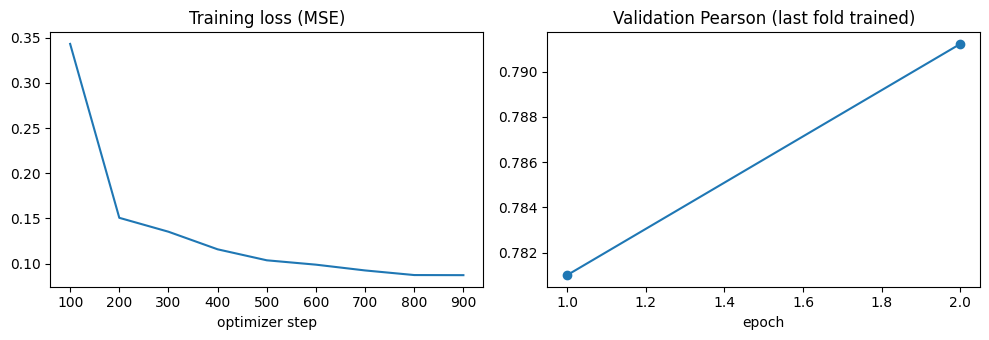

In [43]:
logs = pd.DataFrame(trainer.state.log_history)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))
logs.dropna(subset=["loss"]).plot(x="step", y="loss", ax=ax1, legend=False, title="Training loss (MSE)")
logs.dropna(subset=["eval_pearson"]).plot(x="epoch", y="eval_pearson", marker="o", ax=ax2, legend=False,
                                         title="Validation Pearson (last fold trained)")
ax1.set_xlabel("optimizer step"); ax2.set_xlabel("epoch")
plt.tight_layout(); plt.show()

## 7. Saving and inference

Save the model **and** the tokenizer: the tokenizer now contains the added section tokens, and the model's embedding matrix expects them. At inference there are no labels and no gradients: tokenize, run a forward pass in `eval` mode, and read off the regression output.

In [44]:
trainer.save_model(f"{OUT_DIR}/final")          # also saves the tokenizer (passed as processing_class)

tok = AutoTokenizer.from_pretrained(f"{OUT_DIR}/final")
reloaded = AutoModelForSequenceClassification.from_pretrained(f"{OUT_DIR}/final").eval()

pairs = [("[G] opc drum", "inorganic photoconductor drum"),
         ("[G] opc drum", "steering wheel"),
         ("[B] lower trunnion", "lower locating")]
enc = tok([a for a, _ in pairs], [b for _, b in pairs], padding=True, return_tensors="pt")
with torch.no_grad():
    scores = reloaded(**enc).logits.squeeze(-1)
for (a, b), s in zip(pairs, scores):
    print(f"{s:5.2f}  {a!r} vs {b!r}")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/106 [00:00<?, ?it/s]

 0.57  '[G] opc drum' vs 'inorganic photoconductor drum'
 0.17  '[G] opc drum' vs 'steering wheel'
 0.49  '[B] lower trunnion' vs 'lower locating'


## Review questions

1. What would change in the model, the label dtype, and the loss if we used `num_labels=5`? How would you turn its outputs back into a single similarity score?
2. Why must `resize_token_embeddings` come after `add_special_tokens`? What are the new embedding rows before training?
3. Section 4 compared random and grouped splits. Which validation score would you expect to be higher, and which one better predicts test performance? Why?
4. With `per_device_train_batch_size=16` and `gradient_accumulation_steps=2`, how many optimizer updates happen per epoch on about 29,000 training rows?
5. Training loss keeps falling while validation Pearson stops improving. What is happening, and which `TrainingArguments` setting protects the final model?
6. Can a model have a higher validation Pearson but a worse MSE than another model? Give a small example.
7. Why does this notebook turn the CPC *section* into a special token instead of the full CPC class? What would you try if you wanted to use the full class?
8. A classifier gives the true class of a pair probability 0.6. Does its cross-entropy depend on how it spreads the remaining 0.4 over the other classes? Why does that matter for this task?

## References

- Hugging Face, [Fine-tuning a pretrained model](https://huggingface.co/docs/transformers/training) and the [`Trainer`](https://huggingface.co/docs/transformers/main_classes/trainer) and [`TrainingArguments`](https://huggingface.co/docs/transformers/main_classes/trainer#transformers.TrainingArguments) reference.
- He, P., Gao, J., & Chen, W. (2021). *DeBERTaV3: Improving DeBERTa using ELECTRA-Style Pre-Training with Gradient-Disentangled Embedding Sharing.* arXiv:2111.09543.
- Aslanyan, G., & Wetherbee, I. (2022). *Patents Phrase to Phrase Semantic Matching Dataset.* arXiv:2208.01171.